# Cifar-10 FCN model

Cifar-10 fully connected neural network (FCN) implementation using `Keras` module of the `TensorFlow` library. Keras provides the models and layers used in the classification task.

Import `TensorFlow` as backend before importing the `Keras` library.
Import `Time` to measure the training speed and `matplotlib.pyplot` for visualisation.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
from keras import layers
from keras import backend as K

import time

import numpy as np
import matplotlib.pyplot as plt

C:\Users\miner\anaconda3\envs\keras\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


## Download the data:

Load the Cifar-10 dataset from the keras module. The data fetched is already divided into training and validation datasets. 

The data contains 10 different classes of color images of size 32x32. The classes are: airplane, automobile, bird, cat, deer, dog, frog, horse, ship and truck. 

The training set includes 50 000 images and test set 10 000 images. 

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

print(x_train.shape)

(50000, 32, 32, 3)


The output of the shape shows the number of images (50000), the image size as height and width (32x32) and the RGB format (3) since the images are colored.


For visualization, display a 5x5 grid of the sample images from the training set labeled with its corresponding class name.

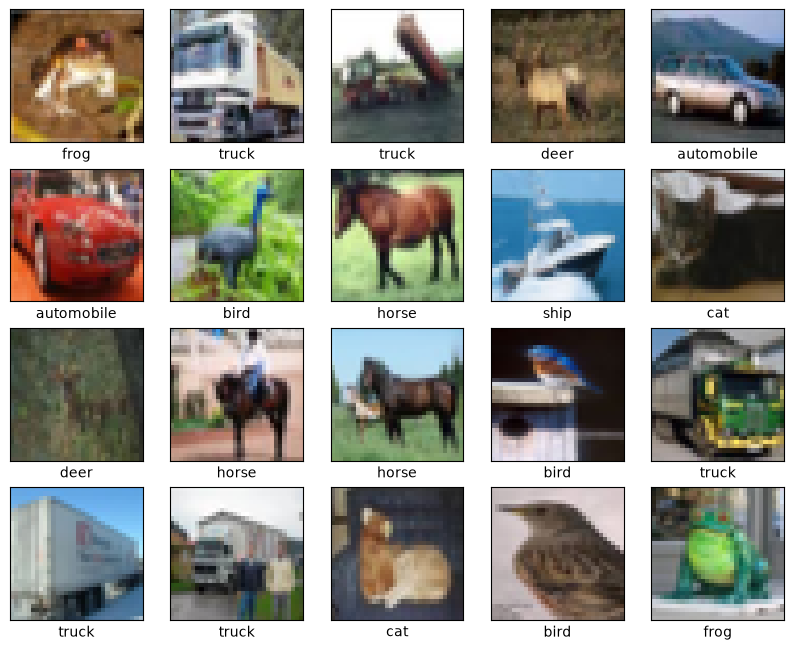

In [3]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(20):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    # The CIFAR labels happen to be arrays, 
    # which is why need the extra index
    plt.xlabel(class_names[y_train[i][0]])
plt.show()

## Preprocess the data:

Before building and training the model, the images are normalized. Since the pixel range of color image is 0-255, each pixel should be divided by 255. Now, the pixel values of each image range from 0-1.

In [4]:
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

## Build the model:

Next the model architecture will be defined. The model is built using the `Sequental API` provided by Keras.

The model consist of 9 layers. First, the input layer defines the shape of the images followed by `RandomFlip` layer for data augmentation. The Flatten layer reshapes the data from 2D table into 1D vector. 

The model has 3 hidden dense layers for learning the feature representation and further processing the learned features.

To reduce overfitting the model uses two different regularization methods: BatchNormalization and Dropout.
During training, BatchNormalization layer standardizes the activations received from the previous dense layer. 
The dropout layer randomly deactivates 30% of neurons received from the previous layer.

The output layer uses SoftMax activation to calculate the probabilities of particular class. The SoftMax function is chosen as it is used for multi-class classification.

In [5]:
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.RandomFlip("horizontal"),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,740,938 (6.64 MB)

 Trainable params: 1,739,914 (6.64 MB)

 Non-trainable params: 1,024 (4.00 KB)

## Compile the model:

Out of the 1 740 938 parameters, only 1 024 (0,06%) were non-trainable parameters.

The `compile` step defines the loss function, the optimizer and the metric. The loss function is `SparseCategoricalCrossentropy` because CIFAR-10 contains 10 differnet classes and the labels are integers from 0 to 9, not one-hot encoded. The optimizer is Adam with default settings, and it is used to update the model weights during training. Accuracy is used as the metric to measure how well the model classifies the images.

In [6]:
model.compile(
    loss=keras.losses.SparseCategoricalCrossentropy(),
    optimizer=keras.optimizers.Adam(),
    metrics=["accuracy"],
)

An `EarlyStopping` callback is used to monitor the validation loss. If the validation loss has not improved for five epocs in a row, the training stops. With `restore_best_weights=True`, the model weights are restored from the epoch with the best value. The model is trained for a maximum of 50 epochs with a batch size 64. 10% of the training data is used as the validation data. Training time is measured with `time.time()`.

In [ ]:
callback = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

t0 = time.time()

history = model.fit(x_train, y_train, epochs=50, batch_size=64,
                    validation_split=0.1, callbacks=[callback], verbose=2)

train_time = time.time() - t0
print(f"Opetusaika: {train_time:.1f} s")

Epoch 1/50
704/704 - 12s - 16ms/step - accuracy: 0.3673 - loss: 1.7762 - val_accuracy: 0.3524 - val_loss: 1.7635
Epoch 2/50
704/704 - 10s - 14ms/step - accuracy: 0.4204 - loss: 1.6330 - val_accuracy: 0.4058 - val_loss: 1.6624
Epoch 3/50
704/704 - 10s - 15ms/step - accuracy: 0.4383 - loss: 1.5834 - val_accuracy: 0.4206 - val_loss: 1.6637
Epoch 4/50


The training stopped after 40 epochs instead of completing all 50 epochs. The best validation loss (1.3151) was at epoch 35. Because it did not improve during the following five epochs, EarlyStopping stopped the training and restored the model weights from epoch 35. Training accuracy increased from 36.8% in the first epoch to 53.8% in the last epoch. Validation accuracy increased from 34.7 % to around 51-53% during last epochs. The training time depends on the computer used, so it can be different on another laptop.

The plots shows training and validation loss and accuracy for each epoch, using the `history` object from `model.fit`. The curves show how the model learns and whether it is overfitting.

In [ ]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

Both training and validation loss curves go down during the training. The training loss decreases smoothly from about 1.78 to 1.29. the validation loss goes from 1.85 to 1.35, but the curve is much more unstable and has several spikes. The gap between curves is small, so the model does not overfit much.

In [ ]:
plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.grid()
plt.show()

The accuracy curves show the same pattern. Training accuracy rises steadily from 37% to about 54%. Validation accuracy rises from 35% to about 53% but fluctuates more. The biggest drop is at epoch 18, where validation accuracy falls from 50% to 44%. Towards the end both curves get flatter and the improvement per epoch is small. This suggests that the FCN is reaching its limit 53-54%, and training for more epochs would probably not help much.

The model is evaluated with the test set of 10 000 images, which the model has not seen during training and validation. The `model.evaluate` function returns the test loss and the test accuracy. This is a reliable way to see how the model works with new, unseen data.

In [ ]:
test_scores = model.evaluate(x_test, y_test, verbose=2)
print("Test loss:", test_scores[0])
print("Test accuracy:", test_scores[1])

The test accuracy is 53.45% and the test loss is 1.315. This means that the model classifies slightly more than half of the test images correctly. The result is within the realistic target of the assignment (50-55 %). The test accuracy is also very close to the validation accuracy. This suggests that the model generalizes reasonably well to unseen images. The values are approximate, as the results may vary slightly between runs and on different computers.

## Image classification result visualization

To see how the model makes its decisions, ten example images from the test set are shown together with the predicted probability for each class. The higher the bar, the more confident the model is that the image belongs to that class.

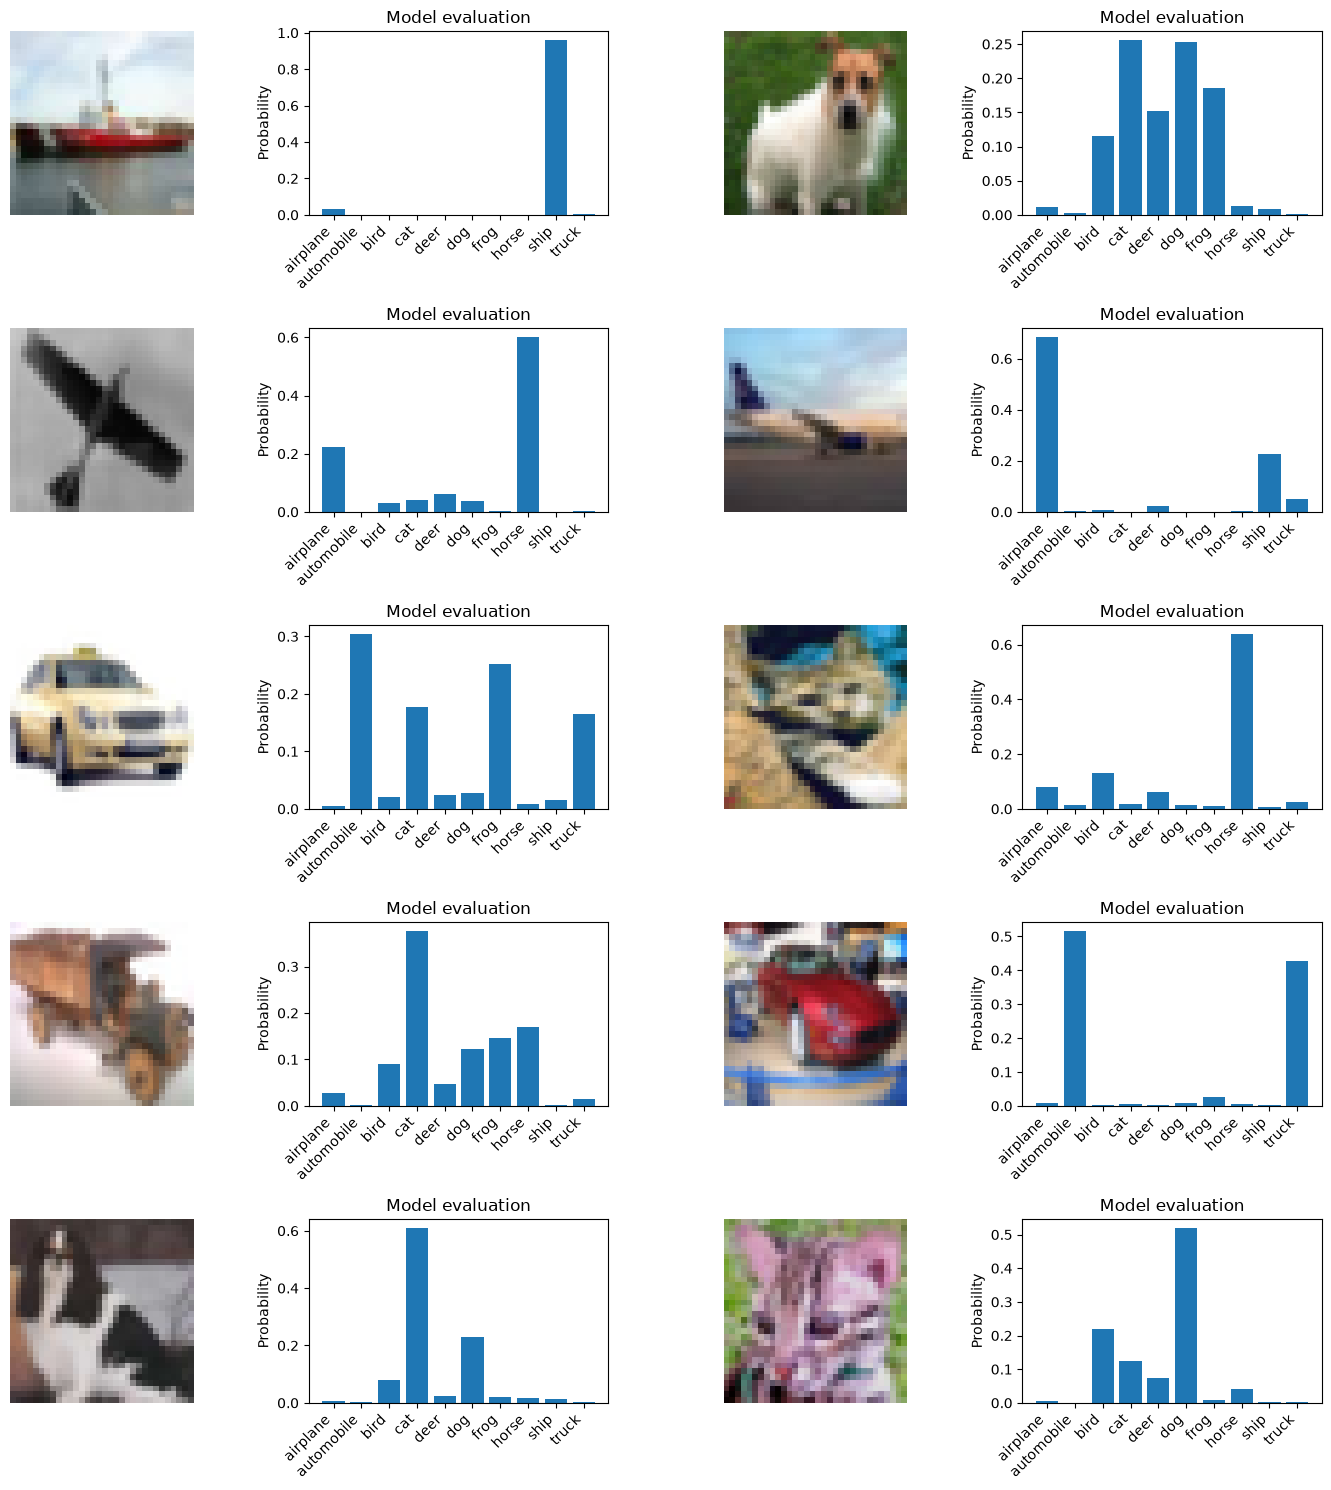

In [31]:
x = x_test
y = model(x)
start = 1900

images_n = 10  # even number
rows = images_n // 2

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[start + k])
    plt.axis("off")

    plt.subplot(rows, 4, 2 * k + 2)
    plt.bar(class_names, y[start + k].numpy().flatten())
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Probability")
    plt.title("Model evaluation")

plt.tight_layout()
plt.show()

The ship and the airplane on the runway are classified with high confidence, but many other predictions are uncertain and the probability is spread over several classes. Some correct predictions are very close: the grey airplane gets almost the same probability for airplane and horse, and the red car is split between automobile and truck.

Most mistakes are between animal classes: a cat is predicted as a horse, a dog as a cat and a cat as a dog. An old truck predicted as a cat shows that the model can also confuse a vehicle with an animal.

The background colour seems to affect the predictions. A blue background raises the probability of ship and airplane, and the dog on green grass gets almost as high a probability for frog as for dog.

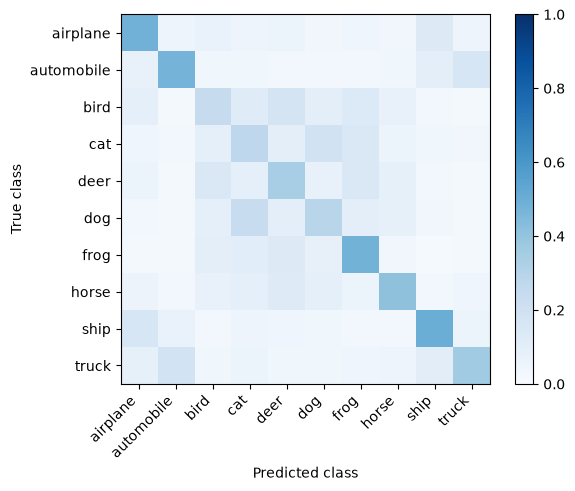

In [30]:
probs = model.predict(x_test, verbose=0)
y_true = y_test.flatten()

mean_probs = [probs[y_true == c].mean(axis=0) for c in range(10)]

plt.imshow(mean_probs, cmap="Blues", vmin=0, vmax=1)
plt.colorbar()
plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.show()

The heatmap shows the average predicted probability for each true class over the test images. Each row is one true class and the diagonal shows how much probability goes to the correct class on average. The darker the square, the higher the average probability.

Airplane, automobile, frog and ship are recognised best, as they have the darkest values on the diagonal, but even these classes get only about half of the probability on average. Bird, cat and dog are the hardest classes: their probability is spread over several animal classes, and cats and dogs are often confused with each other.

Animals are mostly confused with other animals, and vehicles with other vehicles. For example, automobile with truck and airplane with ship. On average there is little overlap between the two groups, so the model separates animals from vehicles fairly well even when it picks the wrong class. This is likely because animals and vehicles usually have different colours and backgrounds. Individual images can still end up in the wrong group, like the truck predicted as a cat in the examples above.

## Test results and conclusions (Riikka)

In order to improve the performance of the model, multiple different versions were tested. The goal was to increase the accuracy score while decreasing the test loss score. The training and validation accuracy and loss scores as well as the training time were also analyzed for the different versions. The tests were performed on one device the results might change if the tests are performed again. Different devices might require a lot more time to train the models. For example, while the final version of the model took around three minutes to train on one device, on another device it tooka around 15 minutes.

The table below shows the different versions that were tested, their accuracy and test loss scores, training time and conclusion about the tested version.

| Test            | Modification                                                                | Accuracy (%) | Test loss |  Training time (s) | Conclusion            |
| --------------- | --------------------------------------------------------------------------- | ------------ | --------- | ------------------ | --------------------- |
| Original model  |                                                                             | 49.97        | 1.408     | 69.2               |The accuracy of the model is not great. Training loss did decrease evenly but the validation loss did not decrease as much. The curves did not curve downwards at an even pace. The model cannot correctly predict most of the time.                |
| Version 1       | Added layer Dropout(0.3)                                                    | 46.50        | 1.530     | 132.7              |The accuracy and test loss scores are slightly worse and the training time increased noticeably, but the training loss and validation loss curves are now more even and the validation loss curve did decrease more.                |
| Version 2       | Added BatchNormalization()                                                  | 50.40        | 1.392     | 93.4               |The accuracy and test loss scores are better than before and training time decreased from the previous version.  Training loss and validation loss curves decreased evenly and the validation curve and values also seemed to become more stable in later epochs after having fluctuated a lot in the begining.                |
| Version 3       | Added Dense(128)                                                            | 50.90        | 1.380     | 64.8               |There is not much of a difference in the accuracy and loss scores but training time did decrease compared to the previous version.                |
| Version 4       | Changed the Dense(128) to Dense(64)                                         | 48.60        | 1.438     | 50.9               |The training time was faster but test accuracy and test loss scores are worse. Fewer neurons made the performance of the model worse.                |
| Version 5       | Changed the Dense(64) back to Dense(128) and added RandomFlip('horizontal') | 53.50        | 1.315     |164.4               |The test accuracy and test loss scores are noticeably better but training time also increased a lot. The model can make better predictions but it is fairly slow to train.                |

Below are the different versions the model that were tested. The versions are shown in their code format to show the placement of the added layers. The "Added layers" spefication under the version specifies which layers were added on to the original model.



**Original model**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
```

**Version 1**<br>
**Added layers: Dropout(0.3)**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
```

**Version 2**<br>
**Added layers: Dropout(0.3), BatchNormalization()**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
```

**Version 3**<br>
**Added layers: Dropout(0.3), BatchNormalization(), Dense(128)**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
```

**Version 4**<br>
**Added layers: Dropout(0.3), BatchNormalization(), Dense(64)**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
```

**Version 5**<br>
**Added layers: Dropout(0.3), BatchNormalization(), Dense(128), RandomFlip("horizontal")**

```python
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.RandomFlip("horizontal"),
    layers.Flatten(),
    layers.Dense(512, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
```

Version 5 was chosen as the final model. It has the best overall perfomance of the tested versions. Testing accuracy was aproximately 53.5%. It correctly classifies little over half of the images. The training time is longer than in the other versions. This is caused by the data augmentation layer: RandomFlip("horizontal"). The layer randomly flips some of the images horizontally, creating a mirrored image, which takes some time since the model needs to make the choice for each image.

The fully connected neural network (FCN) model is not great a correctly identifying targets based on a image. A more complicated model could possibly have a better performance but it would most likely be a lot slower, ecspesically during training, since adding more layers or increasing the number of neurons usually adds more trainable paremeters. 

A convolutional neural network (CNN) models are usually better at handeling image data. A CNN model was created in another part of the assignment. The model and analysis for it can be found in the `cifar-10_CNN` ipynb and html files. Both of these models, FCN and CNN, are also compared more at the end of those files.